# 04. 저장된 결과로 표와 학습곡선 다시 만들기

이 노트북은 저장소에 commit된 표만 읽는다. 서버 자료나 GPU가 없어도 실행된다.

- `reports/transigen_adaptation_b1/tables/test_per_condition.tsv.gz`: 시험 약물 하나, 모델 하나, seed 하나마다 한 줄씩 있는 점수표
- `tables/primary_delta_rmse.tsv`: 보고서의 주지표 표
- `tables/learning_curve_k.tsv`: 적응 약물 수 k에 따른 점수

978개 유전자의 예측 배열 전체는 용량 때문에 서버에 있다. 경로와 SHA-256은 `manifests/transigen_adaptation_b1/final_predictions.json`에 있다.

In [1]:
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
if os.path.basename(os.getcwd()) == "transigen_adaptation_b1": os.chdir(os.path.join("..", ".."))
os.chdir(os.environ.get("TB_ROOT", os.getcwd()))
T = "reports/transigen_adaptation_b1/tables"
pd.set_option("display.width", 160); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8983"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "font.size": 10, "lines.linewidth": 2, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
pc = pd.read_csv(f"{T}/test_per_condition.tsv.gz", sep="\t", dtype={"seed": str})
print(len(pc), "줄 |", pc.target.nunique(), "개 대상 |", pc.model.nunique(), "개 모델·기준선")
pc.head(3)

19619 줄 | 3 개 대상 | 13 개 모델·기준선


,target,split_seed,k,main,role,n_adapt_conditions,n_adapt_rows,n_eval_conditions,model,seed,...,drug_group,delta_rmse,delta_pearson,centred_pearson,top20_direction,top20_recall,retrieval_rank,retrieval_candidates,truth_rms,pred_rms
0,HUH7,1,16,1,test,21,41,16,no_change,-,...,G:BRD-A04706586,0.6807,NaN,0.3133,0.0000,0.0000,8.5000,16,0.6807,0.0000
1,HUH7,1,16,1,test,21,41,16,no_change,-,...,G:BRD-A41649729,0.6299,NaN,0.0706,0.0000,0.0000,8.5000,16,0.6299,0.0000
2,HUH7,1,16,1,test,21,41,16,no_change,-,...,G:BRD-A46802340,0.4625,NaN,0.5983,0.0000,0.0000,8.5000,16,0.4625,0.0000


## 1. 주지표를 직접 다시 계산하기

순서가 중요하다. **약물별 ΔRMSE → 그 분할·seed의 시험 약물 평균 → seed 평균 → 분할 평균.**
seed 세 개의 예측을 먼저 평균한 ensemble은 다른 값이므로 이름에 `_ensemble3`가 붙은 줄로 따로 저장돼 있다. 아래 계산에서는 뺀다.

In [2]:
main = pc[(pc.main == 1) & ~pc.model.str.endswith("_ensemble3")]
per_run = main.groupby(["target", "model", "split_seed", "seed"]).delta_rmse.mean()      # 분할·seed마다 시험 약물 평균
mine = per_run.groupby(["target", "model", "split_seed"]).mean().groupby(["target", "model"]).mean().unstack(0)
saved = pd.read_csv(f"{T}/primary_delta_rmse.tsv", sep="\t").pivot(index="model", columns="target", values="score")
order = [m for m in ["no_change", "target_adapt_mean", "source_same_drug_mean", "source_ridge", "target_ridge", "B0", "b0_mean_offset",
                     "b0_mean_offset_shrunk", "B1_scratch", "B2_finetune"] if m in mine.index]
print("다시 계산한 값과 저장된 표의 최대 차이:", float((mine.loc[order] - saved.loc[order]).abs().max().max()))
mine.loc[order]

다시 계산한 값과 저장된 표의 최대 차이: 4.8833757422261925e-06


target,HUH7,JHH5,JHH7
model,,,
no_change,0.8097,0.5314,0.6924
target_adapt_mean,0.7393,0.5442,0.6821
source_same_drug_mean,0.8204,0.5127,0.6106
source_ridge,0.8570,0.5567,0.6776
target_ridge,0.7358,0.5426,0.6813
B0,1.2394,0.8572,0.9380
b0_mean_offset,0.7131,0.5481,0.6149
b0_mean_offset_shrunk,0.7131,0.5481,0.6149
B1_scratch,2.5878,2.3577,6.6829


## 2. 두 가지 주 대비: B2 − B0, B2 − B1

값이 **음수면 B2가 더 좋다**(RMSE는 작을수록 좋다). 구간은 같은 대상 안에서 약물 그룹을 다시 뽑은 bootstrap 95% 구간이다.
이 구간은 "이 세포주에서 다른 약물을 뽑았다면"에 대한 것이며, 다른 HCC 세포주로의 일반화를 말해 주지 않는다.

In [3]:
con = pd.read_csv(f"{T}/contrasts.tsv", sep="\t")
con[con.metric == "delta_rmse"][["target", "contrast", "diff", "ci_lo", "ci_hi"]].reset_index(drop=True)

,target,contrast,diff,ci_lo,ci_hi
0,HUH7,B2_finetune - B0,-0.4986,-0.5332,-0.4564
1,HUH7,B2_finetune - B1_scratch,-1.8470,-1.8983,-1.8104
2,HUH7,B2_finetune - no_change,-0.0689,-0.1065,-0.0262
3,HUH7,B2_finetune - target_adapt_mean,0.0015,-0.0124,0.0120
4,HUH7,B2_finetune - source_same_drug_mean,-0.0796,-0.1433,-0.0296
5,HUH7,B2_finetune - source_ridge,-0.1162,-0.1447,-0.0834
6,HUH7,B2_finetune - target_ridge,0.0050,-0.0092,0.0161
7,HUH7,B2_finetune - b0_mean_offset,0.0277,0.0146,0.0408
8,HUH7,B2_finetune - b0_mean_offset_shrunk,0.0277,0.0146,0.0408
9,HUH7,b0_mean_offset - B0,-0.5263,-0.5537,-0.4922


## 3. 상관은 약물별로 계산해서 평균한다

모든 약물과 유전자를 한 줄로 이어 붙여 계산한 pooled 상관은 다른 숫자다. 여기서는 약물 하나마다 978개 유전자의 상관을 구한 뒤 평균한다. 무변화(Δ=0)처럼 예측이 상수이면 상관이 정의되지 않으므로 빈칸(NaN)으로 둔다.

In [4]:
sec = main.groupby(["target", "model", "split_seed", "seed"])[["delta_pearson", "centred_pearson", "top20_direction"]].mean()
sec.groupby(["target", "model", "split_seed"]).mean().groupby(["target", "model"]).mean().unstack(0).loc[order].round(3)

delta_pearson               centred_pearson                top20_direction              
target                         HUH7   JHH5   JHH7            HUH7   JHH5    JHH7            HUH7   JHH5   JHH7
model                                                                                                         
no_change                       NaN    NaN    NaN          0.0410 0.0480  0.0990          0.0000 0.0000 0.0000
target_adapt_mean            0.4340 0.0750 0.2680          0.0140 0.0100  0.0450          0.7750 0.5500 0.7260
source_same_drug_mean        0.2810 0.1480 0.3440          0.1340 0.1770  0.3760          0.6700 0.5760 0.7040
source_ridge                 0.1200 0.1010 0.2420          0.0520 0.1170  0.2200          0.6650 0.6050 0.6910
target_ridge                 0.4490 0.0940 0.2690          0.0540 0.0300  0.0520          0.7850 0.5610 0.7330
B0                           0.2000 0.1050 0.2090          0.0490 0.0910  0.1510          0.7370 0.6100 0.6910
b0_mean_offset               0.4640 0.2190 0.3970          0.1650 0.2070  0.3420          0.7930 0.6350 0.7710
b0_mean_offset_shrunk        0.4640 0.2190 0.3970          0.1650 0.2070  0.3420          0.7930 0.6350 0.7710
B1_scratch                   0.3200 0.0800 0.0540          0.0380 0.0650 -0.0110          0.6980 0.5090 0.5660
B2_finetune                  0.4440 0.1570 0.2090          0.1440 0.1450  0.1510          0.7720 0.5820 0.6910

## 4. 학습곡선: 적응 약물 수 k를 바꾸면

첫 번째 분할에서만 k = 8, 16, 32를 실행했다(pool에 없는 크기는 실행하지 않았다). 학습률은 k=16에서 고른 것을 그대로 썼다.

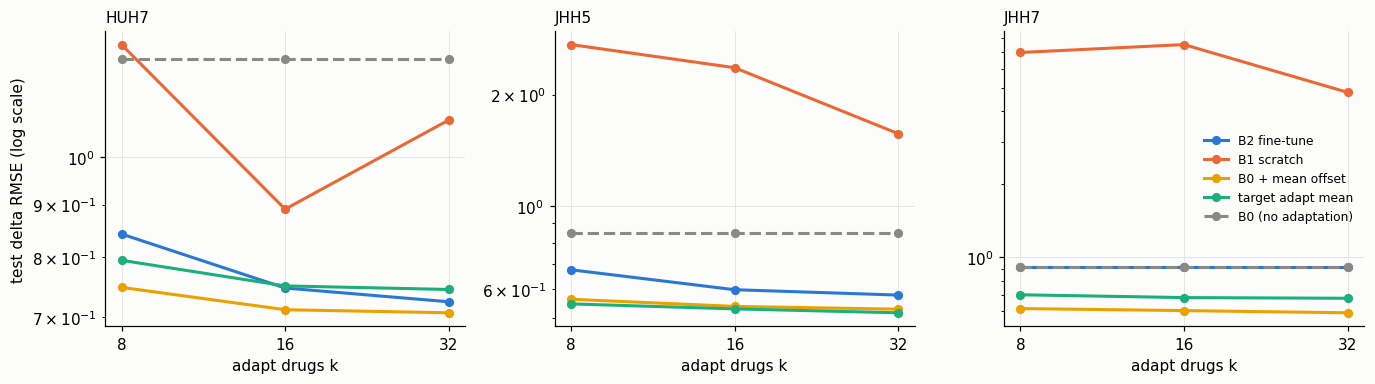

k                                8      16     32
target model                                     
HUH7   B0                    1.2474 1.2474 1.2474
       B1_scratch            1.2869 0.8908 1.0872
       B2_finetune           0.8426 0.7468 0.7242
       b0_mean_offset        0.7478 0.7115 0.7066
       b0_mean_offset_shrunk 0.7478 0.7115 0.7066
       no_change             0.7969 0.7969 0.7969
       source_ridge          0.8426 0.8426 0.8426
       source_same_drug_mean 0.7776 0.7776 0.7776
       target_adapt_mean     0.7946 0.7503 0.7444
       target_ridge          0.8142 0.7492 0.7347
JHH5   B0                    0.8500 0.8500 0.8500
       B1_scratch            2.7277 2.3636 1.5708
       B2_finetune           0.6755 0.5971 0.5775
       b0_mean_offset        0.5627 0.5384 0.5292
       b0_mean_offset_shrunk 0.5627 0.5384 0.5292
       no_change             0.5122 0.5122 0.5122
       source_ridge          0.5425 0.5425 0.5425
       source_same_drug_mean 0.4988 0.4988 0.4988
       target_adapt_mean     0.5469 0.5302 0.5175
       target_ridge          0.5452 0.5289 0.5157
JHH7   B0                    0.9141 0.9141 0.9141
       B1_scratch            6.9957 7.5406 4.7917
       B2_finetune           0.9141 0.9141 0.9141
       b0_mean_offset        0.6159 0.6040 0.5917
       b0_mean_offset_shrunk 0.6159 0.6040 0.5917
       no_change             0.6916 0.6916 0.6916
       source_ridge          0.6586 0.6586 0.6586
       source_same_drug_mean 0.6037 0.6037 0.6037
       target_adapt_mean     0.7019 0.6835 0.6791
       target_ridge          0.7018 0.6833 0.6758

In [5]:
cur = pd.read_csv(f"{T}/learning_curve_k.tsv", sep="\t")
targets = sorted(cur.target.unique())
fig, axes = plt.subplots(1, len(targets), figsize=(4.2 * len(targets), 3.6), squeeze=False)
style = {"B2_finetune": (BLUE, "-", "B2 fine-tune"), "B1_scratch": (ORANGE, "-", "B1 scratch"), "b0_mean_offset": (YELLOW, "-", "B0 + mean offset"),
         "target_adapt_mean": (AQUA, "-", "target adapt mean"), "B0": (GREY, "--", "B0 (no adaptation)")}
for ax, t in zip(axes[0], targets):
    d = cur[cur.target == t]
    for m, (c, ls, lab) in style.items():
        x = d[d.model == m].sort_values("k")
        ax.plot(x.k, x.delta_rmse, color=c, ls=ls, marker="o", ms=5, label=lab)
    ax.set_xscale("log", base=2); ax.set_xticks(sorted(d.k.unique())); ax.set_xticklabels(sorted(d.k.unique()))
    ax.set_yscale("log"); ax.set_title(t, loc="left", fontsize=10); ax.set_xlabel("adapt drugs k")
axes[0][0].set_ylabel("test delta RMSE (log scale)"); axes[0][-1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
cur.pivot_table(index=["target", "model"], columns="k", values="delta_rmse").round(4)

## 읽을 때 주의할 점

- 표의 약물은 "그 HCC 세포주에서 측정되지 않은 것으로 취급한" 약물이다. 다른 세포주(source)에서는 측정된 약물이다. 세상에 처음 나온 약물이 아니다.
- k개 적응 약물 외에 검증 약물도 실제 측정이 필요하다. 그 수는 `RESULTS.md`의 분할 표에 함께 적혀 있다.
- 대상 세포주가 몇 개뿐이므로 평균을 "HCC 전체"의 성능으로 읽지 않는다.